# nanoGPT Hyperparameter Experiments — Group 5


In [ ]:
SMOKE_TEST = False

SLOTS = [(64, 4), (64, 6), (128, 4), (128, 6)]

USE_DRIVE = True            # save results to Google Drive (survives disconnects)
SAVE_CHECKPOINTS = True     # keep each run's final ckpt.pt (~1-20 MB each)
DEVICE = 'cuda'

FIXED = dict(
    learning_rate=1e-3, min_lr=1e-4, warmup_iters=100, beta2=0.99,
    weight_decay=0.1, grad_clip=1.0, gradient_accumulation_steps=1,
    eval_interval=100, eval_iters=50, log_interval=10,
    always_save_checkpoint=False, compile=False, wandb_log=False, bias=False,
)
SAMPLE_ARGS = dict(num_samples=1, max_new_tokens=500, temperature=0.8, top_k=200, seed=1337)

In [ ]:
import os, sys, subprocess, json, re, time, itertools, shutil

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    RESULTS = '/content/drive/MyDrive/nanoGPT_group5_results'
else:
    RESULTS = os.path.abspath('nanoGPT_group5_results')
BASE = '/content' if IN_COLAB else os.path.abspath('.')
REPO = os.path.join(BASE, 'nanoGPT')

if not os.path.exists(os.path.join(REPO, 'train.py')):
    subprocess.run(['git', 'clone', 'https://github.com/karpathy/nanoGPT.git', REPO], check=True)
os.chdir(REPO)
COMMIT = subprocess.run(['git', 'rev-parse', '--short', 'HEAD'], capture_output=True, text=True).stdout.strip()
print('repo:', REPO, '| commit:', COMMIT)

subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'tiktoken'], check=True)  # sample.py imports it
if not os.path.exists('data/shakespeare_char/train.bin'):
    subprocess.run([sys.executable, 'data/shakespeare_char/prepare.py'], check=True)

for d in ['logs', 'samples', 'runs', 'ckpts', 'figures']:
    os.makedirs(os.path.join(RESULTS, d), exist_ok=True)
print('results ->', RESULTS)

Mounted at /content/drive
repo: /content/nanoGPT | commit: 3adf61e
results -> /content/drive/MyDrive/nanoGPT_group5_results


In [ ]:
MARK = '# --- group5 final checkpoint + memory ---'
src = open('train.py').read()
if MARK not in src:
    open('train.py', 'a').write('\n' + MARK + r'''
# Course snippet, fixed: also stores 'config' so sample.py finds meta.pkl
# (without it sample.py silently falls back to GPT-2 BPE and prints garbage).
import torch, os
try:
    torch.save({'model': raw_model.state_dict(), 'model_args': model_args,
                'iter_num': iter_num, 'config': config}, os.path.join(out_dir, 'ckpt.pt'))
    print('Final checkpoint saved to', os.path.join(out_dir, 'ckpt.pt'))
except Exception as e:
    print('Error saving checkpoint:', e)
if torch.cuda.is_available():
    print(f"peak_memory_mb {torch.cuda.max_memory_allocated()/2**20:.1f}")
''')
s = open('sample.py').read()
if 'weights_only=False' not in s:   # newer PyTorch defaults weights_only=True
    s = s.replace('torch.load(ckpt_path, map_location=device)',
                  'torch.load(ckpt_path, map_location=device, weights_only=False)')
    open('sample.py', 'w').write(s)
print('patched')

patched


In [ ]:
GRID = dict(n_head=[4, 8], n_embd=[128, 256], batch_size=[8, 16], max_iters=[1000, 2000], dropout=[0.1, 0.2])

def run_name(c):
    return (f"bs{c['block_size']}_L{c['n_layer']}_H{c['n_head']}_E{c['n_embd']}"
            f"_B{c['batch_size']}_it{c['max_iters']}_do{c['dropout']}")

configs = []
for block_size, n_layer in SLOTS:
    for vals in itertools.product(*GRID.values()):
        c = dict(block_size=block_size, n_layer=n_layer, **dict(zip(GRID, vals)))
        assert c['n_embd'] % c['n_head'] == 0
        c['lr_decay_iters'] = c['max_iters']          # decay ends exactly when training ends
        configs.append(c)
if SMOKE_TEST:
    configs = [dict(c, max_iters=20, lr_decay_iters=20) for c in configs[:2]]
    FIXED.update(eval_interval=10, eval_iters=5, warmup_iters=5, log_interval=5)
    SAMPLE_ARGS.update(max_new_tokens=100)
print(len(configs), 'runs planned')

128 runs planned


In [ ]:
STEP_RE = re.compile(r'step (\d+): train loss ([\d.]+), val loss ([\d.]+)')
ITER_RE = re.compile(r'iter (\d+): loss ([\d.]+), time ([\d.]+)ms')

def parse_log(text):
    evals = [dict(step=int(a), train=float(b), val=float(c)) for a, b, c in STEP_RE.findall(text)]
    iters = [dict(iter=int(a), loss=float(b), ms=float(c)) for a, b, c in ITER_RE.findall(text)]
    params = re.search(r'number of parameters: ([\d.]+)M', text)
    mem = re.search(r'peak_memory_mb ([\d.]+)', text)
    return evals, iters, (float(params.group(1)) if params else None), (float(mem.group(1)) if mem else None)

def run_one(c):
    name = run_name(c)
    result_path = os.path.join(RESULTS, 'runs', name + '.json')
    if os.path.exists(result_path):
        return json.load(open(result_path)), True
    out_dir = os.path.join(BASE, 'out', name)
    args = {**FIXED, **c, 'out_dir': out_dir, 'device': DEVICE, 'dataset': 'shakespeare_char'}
    cmd = [sys.executable, 'train.py', 'config/train_shakespeare_char.py'] + [f'--{k}={v}' for k, v in args.items()]
    t0 = time.time()
    p = subprocess.run(cmd, capture_output=True, text=True)
    wall = time.time() - t0
    log = p.stdout + '\n' + p.stderr
    open(os.path.join(RESULTS, 'logs', name + '.log'), 'w').write(' '.join(cmd) + '\n\n' + log)
    if p.returncode != 0:
        raise RuntimeError(f'{name} failed:\n' + log[-3000:])
    evals, iters, params_m, mem = parse_log(p.stdout)

    sargs = {**SAMPLE_ARGS, 'out_dir': out_dir, 'device': DEVICE}
    s = subprocess.run([sys.executable, 'sample.py'] + [f'--{k}={v}' for k, v in sargs.items()],
                       capture_output=True, text=True)
    if s.returncode != 0:
        sample = 'SAMPLE FAILED\n' + s.stderr[-1500:]
    elif 'Loading meta from' not in s.stdout:
        sample = 'WARNING: meta.pkl not used (GPT-2 encoding)\n' + s.stdout
    else:
        sample = re.split(r'Loading meta from .*?\.\.\.\n', s.stdout, maxsplit=1)[-1].split('---------------')[0]
    open(os.path.join(RESULTS, 'samples', name + '.txt'), 'w').write(sample)

    if SAVE_CHECKPOINTS:
        shutil.copy(os.path.join(out_dir, 'ckpt.pt'), os.path.join(RESULTS, 'ckpts', name + '.pt'))
    shutil.rmtree(out_dir, ignore_errors=True)

    last = evals[-1]
    timed = [i['ms'] for i in iters if i['iter'] >= 20]       # skip warm-up iterations
    r = dict(name=name, **c, params_M=params_m, peak_mem_MB=mem, wall_s=round(wall, 1),
             ms_per_iter=round(sorted(timed)[len(timed)//2], 2) if timed else None,
             final_train=last['train'], final_val=last['val'], gap=round(last['val'] - last['train'], 4),
             best_val=min(e['val'] for e in evals), tokens_seen=c['batch_size'] * c['block_size'] * c['max_iters'],
             evals=evals, iters=iters, commit=COMMIT)
    json.dump(r, open(result_path, 'w'))
    return r, False

results, t_start = [], time.time()
for i, c in enumerate(configs, 1):
    r, cached = run_one(c)
    results.append(r)
    print(f"[{i:3d}/{len(configs)}] {r['name']:<40} val {r['final_val']:.4f} gap {r['gap']:+.4f} "
          f"{r['wall_s']:6.1f}s {'(cached)' if cached else ''}")
print(f'done in {(time.time()-t_start)/60:.1f} min')

[  1/128] bs64_L4_H4_E128_B8_it1000_do0.1          val 2.2690 gap -0.0049   38.2s (cached)
[  2/128] bs64_L4_H4_E128_B8_it1000_do0.2          val 2.3291 gap -0.0091   30.0s (cached)
[  3/128] bs64_L4_H4_E128_B8_it2000_do0.1          val 2.0905 gap +0.0600   51.5s (cached)
[  4/128] bs64_L4_H4_E128_B8_it2000_do0.2          val 2.1565 gap +0.0403   51.5s (cached)
[  5/128] bs64_L4_H4_E128_B16_it1000_do0.1         val 2.1466 gap +0.0435   29.6s (cached)
[  6/128] bs64_L4_H4_E128_B16_it1000_do0.2         val 2.2322 gap +0.0267   30.0s (cached)
[  7/128] bs64_L4_H4_E128_B16_it2000_do0.1         val 1.9670 gap +0.1019   52.8s (cached)
[  8/128] bs64_L4_H4_E128_B16_it2000_do0.2         val 2.0528 gap +0.0582   53.3s (cached)
[  9/128] bs64_L4_H4_E256_B8_it1000_do0.1          val 2.0195 gap +0.0412   29.5s (cached)
[ 10/128] bs64_L4_H4_E256_B8_it1000_do0.2          val 2.0985 gap +0.0194   29.1s (cached)
[ 11/128] bs64_L4_H4_E256_B8_it2000_do0.1          val 1.8818 gap +0.1454   53.7s (cached)

In [ ]:
import pandas as pd
cols = ['name', 'block_size', 'n_layer', 'n_head', 'n_embd', 'batch_size', 'max_iters', 'dropout',
        'params_M', 'peak_mem_MB', 'wall_s', 'ms_per_iter', 'final_train', 'final_val', 'best_val', 'gap', 'tokens_seen']
df = pd.DataFrame(results)[cols].sort_values('final_val').reset_index(drop=True)
df.to_csv(os.path.join(RESULTS, 'summary.csv'), index=False)
pd.set_option('display.width', 220)
print('Best 10 by final validation loss'); display(df.head(10))
print('Worst 5'); display(df.tail(5))

Best 10 by final validation loss


,name,block_size,n_layer,n_head,n_embd,batch_size,max_iters,dropout,params_M,peak_mem_MB,wall_s,ms_per_iter,final_train,final_val,best_val,gap,tokens_seen
0,bs128_L4_H8_E256_B16_it2000_do0.1,128,4,8,256,16,2000,0.1,3.16,231.8,79.8,25.95,1.4685,1.6581,1.6581,0.1896,4096000
1,bs128_L4_H4_E256_B16_it2000_do0.1,128,4,4,256,16,2000,0.1,3.16,195.8,72.9,23.54,1.4780,1.6616,1.6616,0.1836,4096000
2,bs128_L6_H8_E256_B16_it2000_do0.1,128,6,8,256,16,2000,0.1,4.74,333.8,114.9,38.59,1.4612,1.6624,1.6403,0.2012,4096000
3,bs128_L6_H4_E256_B16_it2000_do0.1,128,6,4,256,16,2000,0.1,4.74,280.9,104.9,35.21,1.4713,1.6682,1.6459,0.1969,4096000
4,bs128_L4_H8_E256_B16_it2000_do0.2,128,4,8,256,16,2000,0.2,3.16,231.8,79.4,26.12,1.5625,1.7264,1.7264,0.1639,4096000
5,bs128_L6_H4_E256_B16_it2000_do0.2,128,6,4,256,16,2000,0.2,4.74,280.9,104.6,35.35,1.5621,1.7454,1.7290,0.1833,4096000
6,bs128_L4_H4_E256_B16_it2000_do0.2,128,4,4,256,16,2000,0.2,3.16,195.8,72.6,23.72,1.5733,1.7523,1.7523,0.1790,4096000
7,bs128_L6_H8_E256_B16_it2000_do0.2,128,6,8,256,16,2000,0.2,4.74,333.8,114.6,38.66,1.5751,1.7534,1.7413,0.1783,4096000
8,bs64_L4_H8_E256_B16_it2000_do0.1,64,4,8,256,16,2000,0.1,3.16,125.6,54.8,15.51,1.5843,1.7592,1.7565,0.1749,2048000
9,bs64_L4_H4_E256_B16_it2000_do0.1,64,4,4,256,16,2000,0.1,3.16,116.2,54.6,15.51,1.5885,1.7683,1.7683,0.1798,2048000


Worst 5


,name,block_size,n_layer,n_head,n_embd,batch_size,max_iters,dropout,params_M,peak_mem_MB,wall_s,ms_per_iter,final_train,final_val,best_val,gap,tokens_seen
123,bs128_L6_H4_E128_B8_it1000_do0.2,128,6,4,128,8,1000,0.2,1.19,95.0,34.4,19.67,2.2889,2.3108,2.2949,0.0219,1024000
124,bs64_L4_H8_E128_B8_it1000_do0.2,64,4,8,128,8,1000,0.2,0.80,48.3,30.9,14.70,2.3303,2.3192,2.3192,-0.0111,512000
125,bs128_L4_H4_E128_B8_it1000_do0.2,128,4,4,128,8,1000,0.2,0.80,69.7,28.5,15.86,2.3182,2.3251,2.3251,0.0069,1024000
126,bs128_L4_H8_E128_B8_it1000_do0.2,128,4,8,128,8,1000,0.2,0.80,90.0,26.5,13.81,2.3193,2.3259,2.3259,0.0066,1024000
127,bs64_L4_H4_E128_B8_it1000_do0.2,64,4,4,128,8,1000,0.2,0.80,43.8,30.0,15.10,2.3382,2.3291,2.3291,-0.0091,512000


,hyperparameter,low,high,val_low,val_high,delta_val,delta_gap,time_ratio
3,n_embd,128.0,256.0,2.1350,1.9130,-0.2220,0.0735,1.1566
5,max_iters,1000.0,2000.0,2.1193,1.9288,-0.1905,0.0642,1.8255
4,batch_size,8.0,16.0,2.0875,1.9606,-0.1269,0.0441,1.1465
0,block_size,64.0,128.0,2.0410,2.0071,-0.0339,0.0191,1.0776
1,n_layer,4.0,6.0,2.0313,2.0167,-0.0146,0.0044,1.3244
2,n_head,4.0,8.0,2.0233,2.0248,0.0015,0.0002,1.0066
6,dropout,0.1,0.2,1.9835,2.0646,0.0812,-0.0240,1.0040


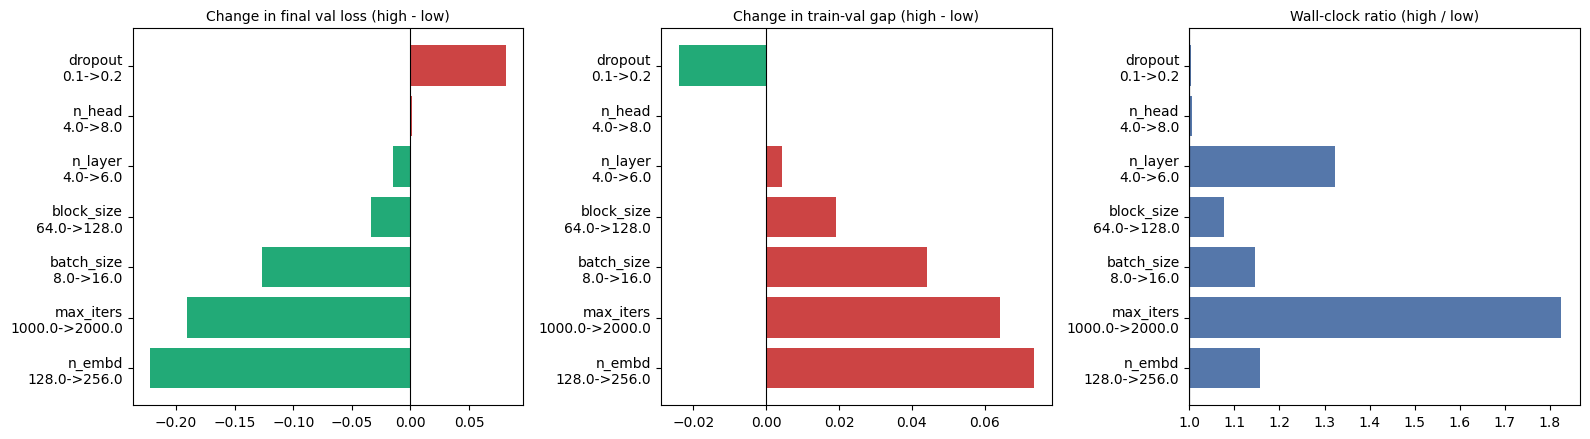

In [ ]:
import matplotlib.pyplot as plt
HP = ['block_size', 'n_layer', 'n_head', 'n_embd', 'batch_size', 'max_iters', 'dropout']
hp = [h for h in HP if df[h].nunique() > 1]
effects = []
for h in hp:
    g = df.groupby(h)[['final_val', 'gap', 'wall_s', 'params_M']].mean()
    lo, hi = g.index.min(), g.index.max()
    effects.append(dict(hyperparameter=h, low=lo, high=hi,
                        val_low=g.loc[lo, 'final_val'], val_high=g.loc[hi, 'final_val'],
                        delta_val=g.loc[hi, 'final_val'] - g.loc[lo, 'final_val'],
                        delta_gap=g.loc[hi, 'gap'] - g.loc[lo, 'gap'],
                        time_ratio=g.loc[hi, 'wall_s'] / g.loc[lo, 'wall_s']))
eff = pd.DataFrame(effects).sort_values('delta_val')
eff.to_csv(os.path.join(RESULTS, 'main_effects.csv'), index=False)
display(eff.round(4))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col, title in zip(axes, ['delta_val', 'delta_gap', 'time_ratio'],
                          ['Change in final val loss (high - low)', 'Change in train-val gap (high - low)',
                           'Wall-clock ratio (high / low)']):
    base = 1 if col == 'time_ratio' else 0
    ax.barh([f"{r.hyperparameter}\n{r.low}->{r.high}" for r in eff.itertuples()], eff[col] - base, left=base,
            color=['#2a7' if v < base else '#c44' for v in eff[col]] if col != 'time_ratio' else '#57a')
    ax.axvline(base, color='k', lw=0.8); ax.set_title(title, fontsize=10)
plt.tight_layout(); plt.savefig(os.path.join(RESULTS, 'figures', 'main_effects.png'), dpi=150); plt.show()

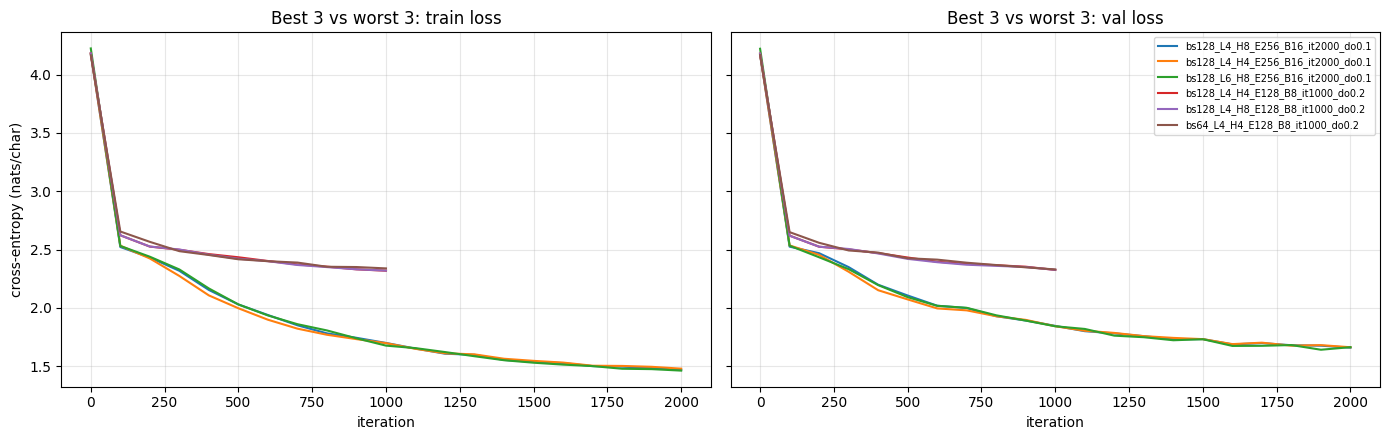

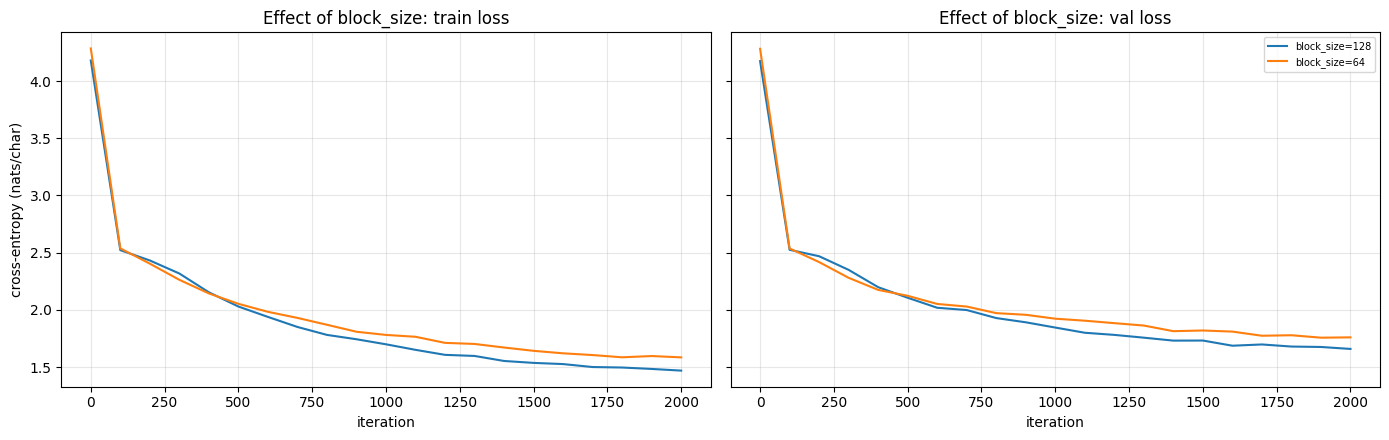

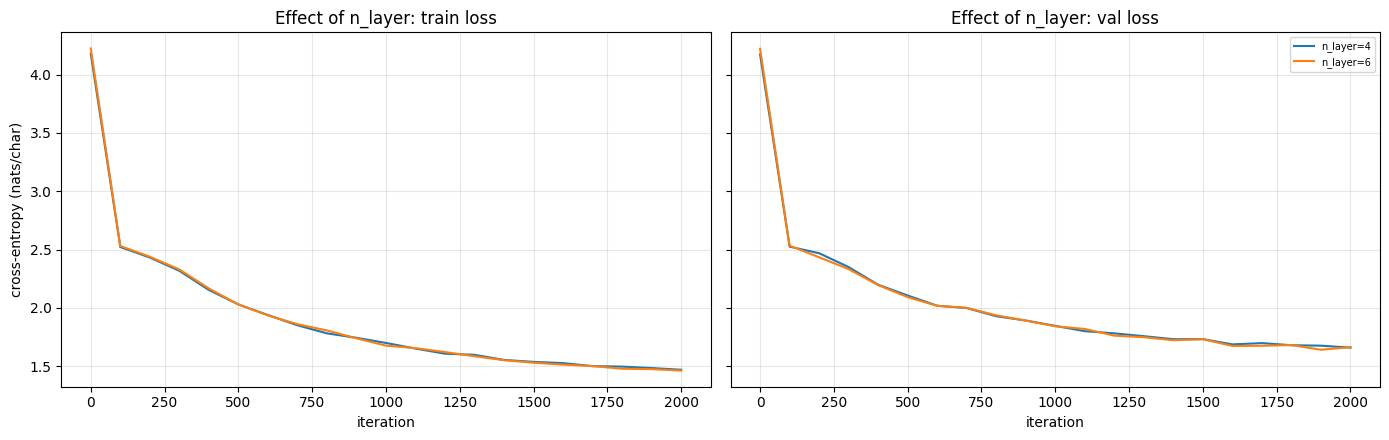

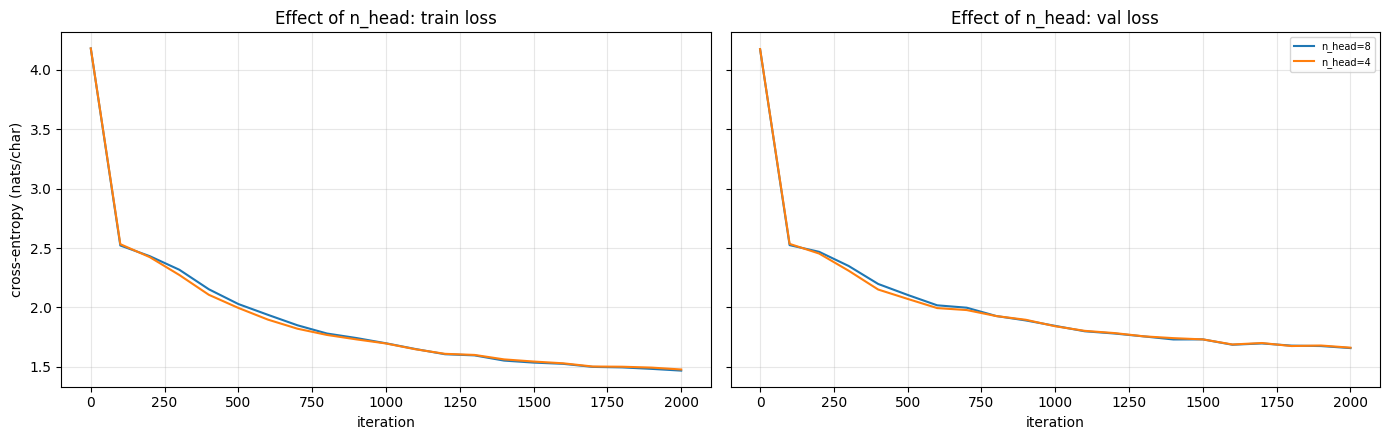

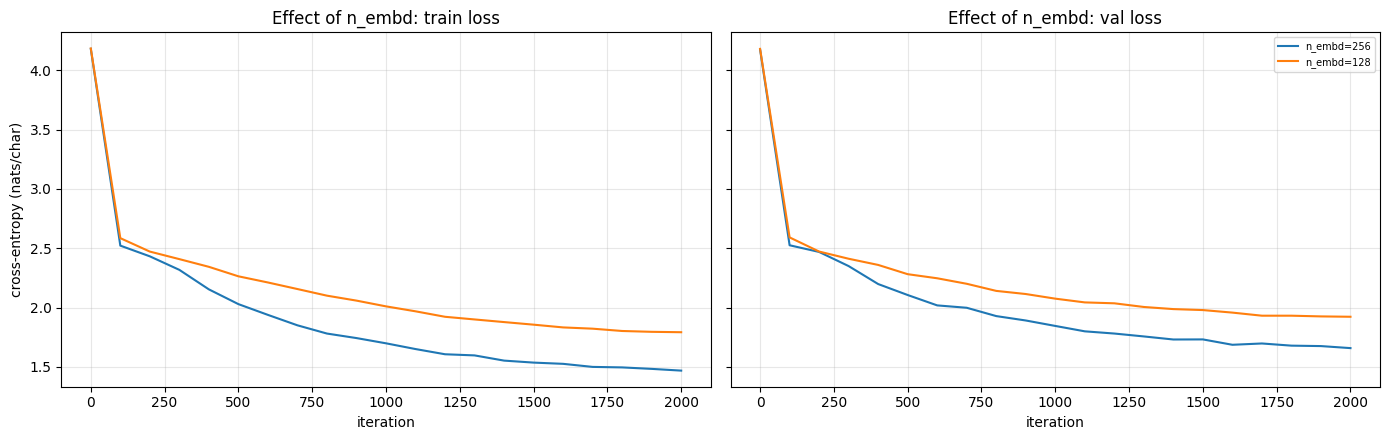

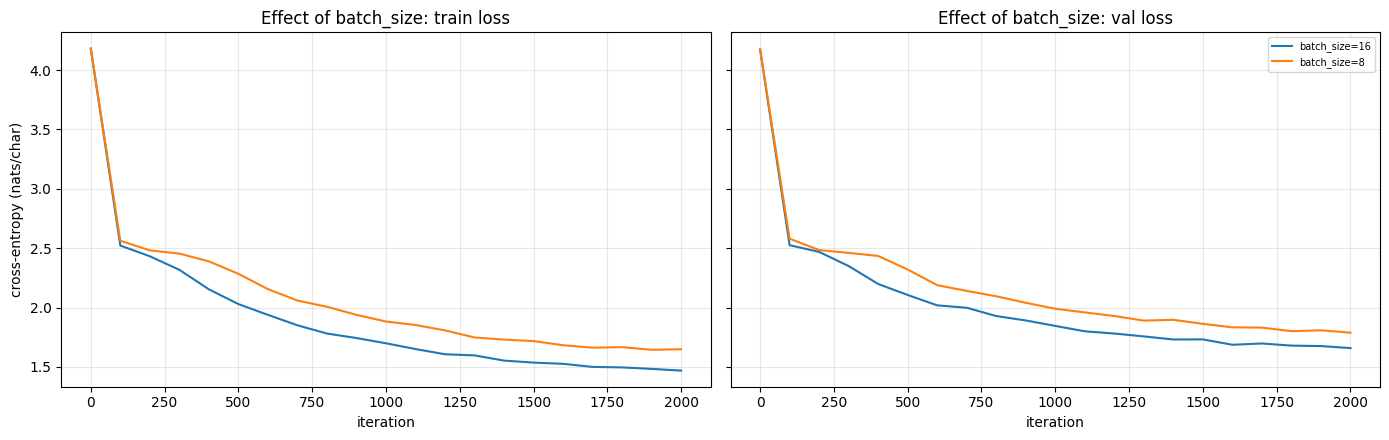

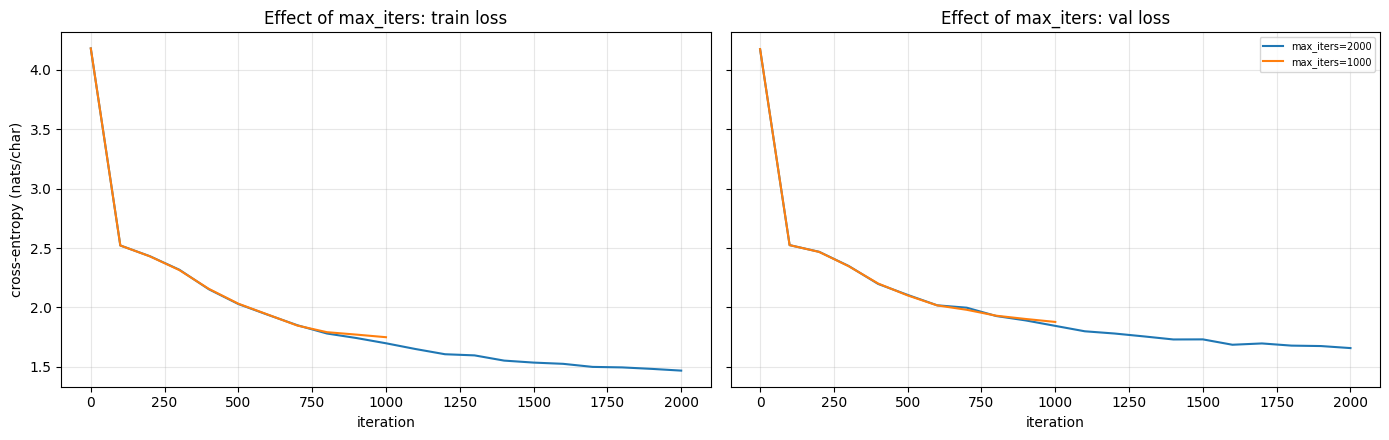

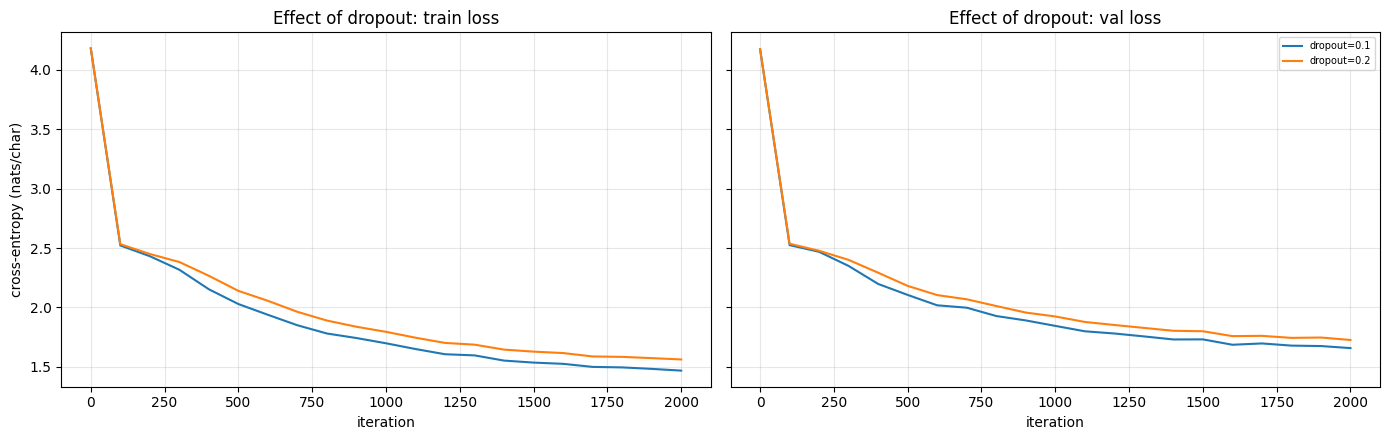

In [ ]:
def curves(sub, title, fname, label_fn):
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
    for r in sub:
        st = [e['step'] for e in r['evals']]
        l, = ax[0].plot(st, [e['train'] for e in r['evals']], label=label_fn(r))
        ax[1].plot(st, [e['val'] for e in r['evals']], color=l.get_color(), label=label_fn(r))
    for a, t in zip(ax, ['train loss', 'val loss']):
        a.set_title(f'{title}: {t}'); a.set_xlabel('iteration'); a.grid(alpha=.3)
    ax[0].set_ylabel('cross-entropy (nats/char)'); ax[1].legend(fontsize=7, loc='upper right')
    plt.tight_layout(); plt.savefig(os.path.join(RESULTS, 'figures', fname), dpi=150); plt.show()

by = {r['name']: r for r in results}
# (a) best and worst 3 runs overall
order = df['name'].tolist()
curves([by[n] for n in order[:3] + order[-3:]], 'Best 3 vs worst 3', 'best_worst.png', lambda r: r['name'])
# (b) one-factor-at-a-time around the best run: flip each hyperparameter
best = by[order[0]]
for h in hp:
    other = [r for r in results if r[h] != best[h] and all(r[k] == best[k] for k in hp if k != h)]
    if other:
        curves([best] + other, f'Effect of {h}', f'effect_{h}.png', lambda r, h=h: f'{h}={r[h]}')

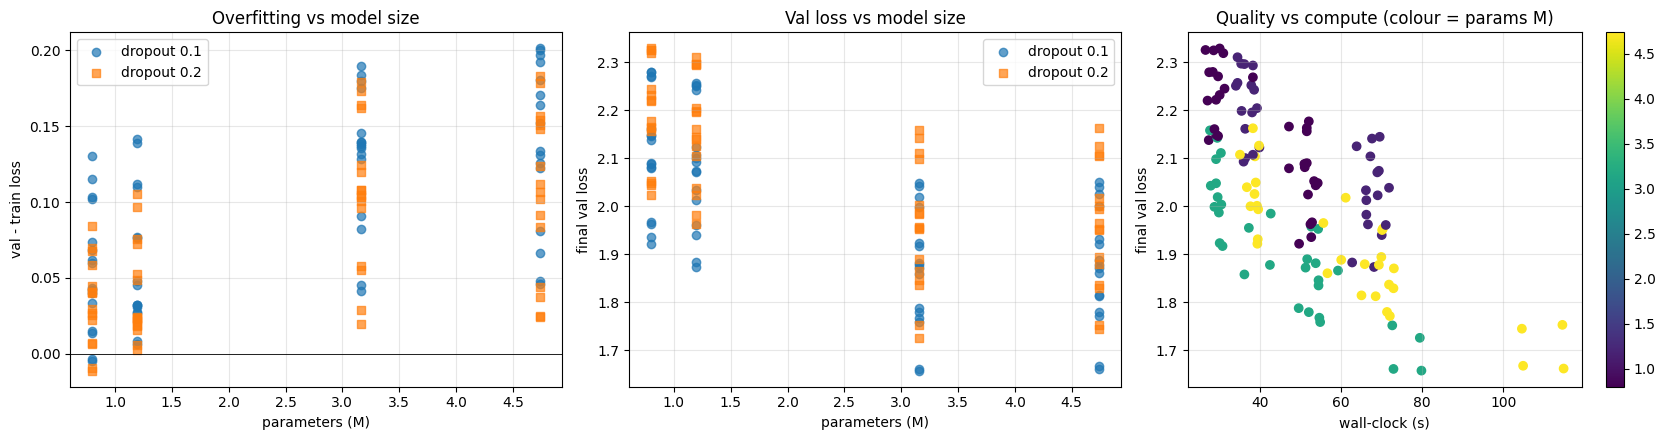

n_embd                 128     256
block_size n_layer                
64         4        2.1540  1.9385
           6        2.1320  1.9393
128        4        2.1508  1.8820
           6        2.1032  1.8923

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for d, m in [(0.1, 'o'), (0.2, 's')]:
    s = df[df.dropout == d]
    ax[0].scatter(s.params_M, s.gap, marker=m, label=f'dropout {d}', alpha=.7)
    ax[1].scatter(s.params_M, s.final_val, marker=m, label=f'dropout {d}', alpha=.7)
ax[0].set(xlabel='parameters (M)', ylabel='val - train loss', title='Overfitting vs model size'); ax[0].axhline(0, c='k', lw=.6)
ax[1].set(xlabel='parameters (M)', ylabel='final val loss', title='Val loss vs model size')
sc = ax[2].scatter(df.wall_s, df.final_val, c=df.params_M, cmap='viridis')
ax[2].set(xlabel='wall-clock (s)', ylabel='final val loss', title='Quality vs compute (colour = params M)')
plt.colorbar(sc, ax=ax[2])
for a in ax[:2]: a.legend()
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(RESULTS, 'figures', 'overfit_cost.png'), dpi=150); plt.show()

# Heat-map: mean val loss for n_layer x n_embd within each block_size
piv = df.pivot_table(index=['block_size', 'n_layer'], columns='n_embd', values='final_val', aggfunc='mean')
display(piv.round(4))

In [ ]:
for n in [order[0], order[len(order)//2], order[-1]]:
    print('=' * 90); print(n, f"| val {by[n]['final_val']:.4f}"); print('=' * 90)
    print(open(os.path.join(RESULTS, 'samples', n + '.txt')).read()[:600])

bs128_L4_H8_E256_B16_it2000_do0.1 | val 1.6581


All before we will to life.

LEONTES:
But the answer'd the gate
My Lord hath heart to be deter's fear.

HENRY BOLINGBROKE:
What what to that I can it now
Which your may hail latest in the speak;
Where his beling self in you here she country:
As I am speak you love.
I was parel you have you, to that
more not your pity sover more to Edward,
We will have his burther mother, an so;
And he must with all of which Prince, So my fault,
Harried is a rose counter for his blook accase
His from hands caren

bs64_L6_H4_E256_B8_it1000_do0.1 | val 2.0260

And they bridcow and is so be madiest bobe to tanthend my call ands:
Whith foul his to bard that ane aw crome.

HARENY:
Gorome
You, Lith tis heart my well in, es is ensen cin latiser,
Wor the and the now on that thell in you his hus wor him sprape ands
Withy moll and nothe and a do hom the the to agleon in on her evicks to ther,
Will with is he poot of his but that non this fron; is hin shis thy all o

### Optional: given checkpoint (`ckpt-1.pt` + `meta.pkl`)

In [ ]:
import torch, pickle
sys.path.insert(0, REPO)
from model import GPTConfig, GPT
if os.path.exists(os.path.join(BASE, 'ckpt-1.pt')):
    ck = torch.load(os.path.join(BASE, 'ckpt-1.pt'), map_location=DEVICE, weights_only=False)
    print(ck['model_args'])
    m = GPT(GPTConfig(**ck['model_args'])); m.load_state_dict(ck['model']); m.eval().to(DEVICE)
    meta = pickle.load(open(os.path.join(BASE, 'meta.pkl'), 'rb'))
    stoi, itos = meta['stoi'], meta['itos']
    torch.manual_seed(1337)
    x = torch.tensor([[stoi[ch] for ch in 'ROMEO:']], device=DEVICE)
    print(''.join(itos[i] for i in m.generate(x, 400, temperature=0.8, top_k=200)[0].tolist()))
else:
    print('Upload ckpt-1.pt and meta.pkl to /content to run this cell.')

Upload ckpt-1.pt and meta.pkl to /content to run this cell.


In [ ]:
pkg = os.path.join(BASE, 'github_package')
shutil.rmtree(pkg, ignore_errors=True)
shutil.copytree(RESULTS, pkg, ignore=shutil.ignore_patterns('ckpts'))
json.dump(dict(fixed=FIXED, grid=GRID, slots=SLOTS, sample=SAMPLE_ARGS, nanogpt_commit=COMMIT),
          open(os.path.join(pkg, 'experiment_config.json'), 'w'), indent=2)
shutil.make_archive(os.path.join(BASE, 'nanoGPT_group5_results'), 'zip', pkg)
print('zip ->', os.path.join(BASE, 'nanoGPT_group5_results.zip'))
if IN_COLAB:
    from google.colab import files; files.download(os.path.join(BASE, 'nanoGPT_group5_results.zip'))

zip -> /content/nanoGPT_group5_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>